<a href="https://colab.research.google.com/github/David-NNdungu/econ5200-aa-usairways-final-project/blob/main/Airline_Merger_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# American–US Airways Merger: Proposal and Preliminary EDA
**David Njihia Ndungu | ECON 5200 | Milestone 1 | November 23, 2026**

This notebook completes **Part 2 of the course final-project starter**. It is exploratory work, not a completed causal analysis. All calculations run in Python. The supplied Stata scripts are provenance documents; Stata is not needed.

**Colab:** upload this notebook, select Runtime > Run all, and select `airline_panel.csv` when prompted. **Jupyter:** place the CSV beside the notebook and run all cells. No API key is needed. The CSV is a direct export of my supplied `panel_2011_2016.dta`; it is not a new raw BTS download.

My EDA uses an **equal-weight average of the supplied carrier fares within a route-quarter**, not a passenger-weighted traveler fare. The saved passenger field was produced with analytic-weighted sums and needs rebuilding from the original ticket records before it can be used as a count or passenger weight.

## Part 0: Python setup

In [1]:
from pathlib import Path
import sys
import importlib.util
import subprocess
needed = [p for p in ["pandas", "numpy", "matplotlib"] if importlib.util.find_spec(p) is None]
if needed:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *needed])
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
RANDOM_STATE = 42
OUTPUT = Path("eda_outputs")
OUTPUT.mkdir(exist_ok=True)
print("Python setup complete.")

Python setup complete.


## Part 2: The decision, the design, and the data

### 2.1 Client and decision
My proposed client is the U.S. Department of Justice Antitrust Division. I would use this retrospective to advise whether overlap routes deserve closer fare monitoring and review of entry conditions after a merger. For this project, a sustained **5% causal fare increase** is my proposed threshold for closer review; it is a planning rule, not a legal standard or an automatic finding of harm. I would assess uncertainty and identification before recommending action.

### 2.2 Why prediction is not enough
Overlap routes may have higher fares because they are longer, denser, or serve different demand. A good fare-prediction model cannot distinguish those differences from the effect of eliminating a competitor. A simple before-after comparison also mixes the merger with common fuel-price and economic changes.

### 2.3 Identification strategy
I propose a common-date **difference-in-differences (DiD)** design: compare changes on pre-merger overlap routes with changes on routes with neither AA nor US carrier codes before the merger. I exclude 2013 and define the post period as 2014–2016. The intended estimand is an average merger effect for the retained overlap routes, conditional on a credible comparison and reliable fare measurement, rather than an effect for all U.S. travelers.

A treated route has AA and US carrier codes **in the same quarter** at least once during 2011–2012. I exclude routes with only one merging-carrier code and routes first observed after 2012. Treatment is fixed using pre-merger information. An affiliate-to-parent carrier audit is still needed; code presence is not proof of independent airline competition.

The key assumption is parallel untreated fare trends after conditioning on pre-merger route characteristics, with no important merger spillovers onto controls. I will compare pre-period event-study leads and common support in distance, initial fare and carrier count. I will not keep changing the sample merely to obtain a non-significant pre-trend test. If the comparison remains unsuitable, I will report a descriptive result or sensitivity range instead of claiming causality.

My main feared threat is stronger business-demand growth on overlap routes: if it raises their fares even without the merger, the DiD estimate is biased **upward**. I will also examine spillovers and changes in the routes observed. Matching will use pre-merger variables only. I will not automatically control for post-merger traffic, concentration or entry because these may be mechanisms of the merger itself.

For later analysis I propose route and year-quarter fixed effects and route-clustered standard errors. Shared airport shocks remain a reason to check alternative clustering. The treated-route count is calculated below; it does not represent that many independently randomised mergers.

In [2]:
ACTION_THRESHOLD_PCT = 5
print(f"Proposed decision threshold: {ACTION_THRESHOLD_PCT}% sustained causal fare increase.")
print("Design: common-date DiD; pre 2011–2012; post 2014–2016; transition year 2013 excluded.")

Proposed decision threshold: 5% sustained causal fare increase.
Design: common-date DiD; pre 2011–2012; post 2014–2016; transition year 2013 excluded.


### 2.4 Load the data and verify provenance
Source: [BTS DB1B Market](https://www.transtats.bts.gov/DatabaseInfo.asp?QO_VQ=EFI&Yv0x=D), the historical quarterly 10% ticket survey. The supplied panel has already been cleaned and collapsed to route-carrier-quarter. Its columns do not allow me to recheck raw bulk-fare, nonstop, geographic or directional aggregation decisions. I audit what is actually observable here rather than claim to have rerun the raw pipeline.

In [3]:
data_path = Path("airline_panel.csv")
if not data_path.exists():
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError("Place airline_panel.csv beside this notebook, then run again.")
    print("Select airline_panel.csv from your computer.")
    uploaded = files.upload()
    if "airline_panel.csv" not in uploaded:
        raise FileNotFoundError("The selected upload must be named airline_panel.csv.")
source_sha256 = hashlib.sha256(data_path.read_bytes()).hexdigest()
carrier = pd.read_csv(data_path, dtype={"route": str, "opcarrier": str})
carrier.columns = carrier.columns.str.lower().str.strip()
required = ["route", "opcarrier", "year", "quarter", "mktfare", "passengers", "mktdistance"]
assert set(required).issubset(carrier.columns), "Missing required data columns"
carrier["route"] = carrier["route"].str.strip().str.upper()
carrier["opcarrier"] = carrier["opcarrier"].str.strip().str.upper()
for col in ["year", "quarter", "mktfare", "passengers", "mktdistance"]:
    carrier[col] = pd.to_numeric(carrier[col], errors="raise")
print("Input file SHA-256:", source_sha256)
print(f"Supplied route-carrier-quarter rows: {len(carrier):,}")
print(f"Routes: {carrier.route.nunique():,}; carriers: {carrier.opcarrier.nunique()}")
display(carrier.head())

Select airline_panel.csv from your computer.


Saving airline_panel.csv to airline_panel.csv
Input file SHA-256: 2d525397a8073eb0c2650b0cc890d027bbf993e15869474e11e1038483596759
Supplied route-carrier-quarter rows: 140,026
Routes: 3,126; carriers: 65


,year,quarter,opcarrier,route,mktfare,passengers,mktdistance
0,2011,1,9E,ABE_ATL,206.98819,7.727273,692.0
1,2011,1,DL,ABE_ATL,271.07500,4.000000,692.0
2,2011,1,EV,ABE_ATL,221.97643,467.874110,692.0
3,2011,1,US,ABE_ATL,221.08238,44.380952,692.0
4,2011,1,UA,ABE_CLT,112.51000,1.000000,481.0


### 2.5 Missing values, duplicate keys, and sample rules

In [4]:
print("Missing values in required fields:")
display(carrier[required].isna().sum().to_frame("missing"))
key = ["route", "opcarrier", "year", "quarter"]
print("Duplicate route-carrier-quarter keys:", carrier.duplicated(key).sum())
assert not carrier[required].isna().any().any()
assert not carrier.duplicated(key).any()
assert carrier.year.isin([2011, 2012, 2014, 2015, 2016]).all()
assert carrier.quarter.isin([1, 2, 3, 4]).all()
assert carrier.mktfare.between(25, 1500).all()
assert (carrier.passengers > 0).all()
print("Observed years:", sorted(carrier.year.unique().tolist()))
print("Observed year-quarters:", carrier[["year", "quarter"]].drop_duplicates().shape[0])
print("Saved fare range:", carrier.mktfare.min(), "to", carrier.mktfare.max())

Missing values in required fields:


,missing
route,0
opcarrier,0
year,0
quarter,0
mktfare,0
passengers,0
mktdistance,0


Duplicate route-carrier-quarter keys: 0
Observed years: [2011, 2012, 2014, 2015, 2016]
Observed year-quarters: 20
Saved fare range: 25.0 to 1268.655


### 2.6 Audit of the saved passenger field
The legacy scripts run `collapse (mean) mktfare (sum) passengers ... [aweight=passengers]`, and then collapse again with analytic weights. Stata documents that `sum` under analytic weights uses normalised weights; it is not the unweighted raw sum. The resulting passenger field therefore cannot be treated as a sampled-ticket count. The scripts also apply the traffic screen before combining directions, at the directional carrier-quarter level, not the final route-quarter level.

I retain the stored carrier fare as a preliminary input, and give each carrier record equal weight within route-quarter. This avoids using the questionable field a second time, but it does **not** undo any earlier aggregation or selection issues. It is a proxy, not an estimate of the average fare paid by a traveler. I need the original records to rebuild fare revenue `sum(fare * passengers)` and passenger totals `sum(passengers)` separately, then divide the totals after aggregation.

Documentation: [Stata collapse manual](https://www.stata.com/manuals/dcollapse.pdf).

In [5]:
fractional_weight_rows = int((~np.isclose(carrier.passengers, carrier.passengers.round(), rtol=0, atol=1e-6)).sum())
print(f"Saved passenger values that are not integer counts: {fractional_weight_rows:,}")
print(f"Saved rows below 180 in that field: {(carrier.passengers < 180).sum():,}")
print("I do not apply a new passenger floor or claim passenger-weighted fares from this field.")

Saved passenger values that are not integer counts: 113,545
Saved rows below 180 in that field: 65,487
I do not apply a new passenger floor or claim passenger-weighted fares from this field.


### 2.7 Fix treatment status using the pre-merger period

In [6]:
pre_carrier = carrier.loc[carrier.year <= 2012].copy()
code_sets = pre_carrier.groupby("route").opcarrier.agg(set)
any_aa_us = code_sets.map(lambda codes: bool({"AA", "US"} & codes))
both_ever = code_sets.map(lambda codes: {"AA", "US"}.issubset(codes))
same_quarter = (pre_carrier.groupby(["route", "year", "quarter"]).opcarrier
                .agg(lambda codes: {"AA", "US"}.issubset(set(codes)))
                .groupby("route").any())
treated_routes = same_quarter.index[same_quarter].tolist()
control_routes = any_aa_us.index[~any_aa_us].tolist()
status = pd.Series({r: 1 for r in treated_routes} | {r: 0 for r in control_routes}, name="treated")
assert set(treated_routes).isdisjoint(control_routes)
print(f"Pre-existing routes: {len(code_sets):,}")
print(f"Both AA and US ever present in the pre-period: {int(both_ever.sum()):,}")
print(f"Both present in at least one SAME pre-merger quarter (treated): {len(treated_routes):,}")
print(f"Neither AA nor US in any pre-merger quarter (comparison): {len(control_routes):,}")
print(f"Pre-existing routes excluded from this comparison: {len(code_sets) - len(status):,}")
print(f"Routes first observed after 2012, excluded: {carrier.route.nunique() - len(code_sets):,}")

Pre-existing routes: 2,645
Both AA and US ever present in the pre-period: 475
Both present in at least one SAME pre-merger quarter (treated): 418
Neither AA nor US in any pre-merger quarter (comparison): 1,235
Pre-existing routes excluded from this comparison: 992
Routes first observed after 2012, excluded: 481


### 2.8 Build the route-quarter EDA panel in Python

In [7]:
route_quarter = (carrier.groupby(["route", "year", "quarter"], as_index=False)
    .agg(fare_proxy=("mktfare", "mean"), distance=("mktdistance", "mean"),
         carrier_count=("opcarrier", "nunique")))
print(f"All observed route-quarters before comparison restrictions: {len(route_quarter):,}")
eda = route_quarter.loc[route_quarter.route.isin(status.index)].copy()
eda["treated"] = eda.route.map(status).astype(int)
eda["post"] = (eda.year >= 2014).astype(int)
eda["period"] = pd.PeriodIndex.from_fields(year=eda.year.astype(int), quarter=eda.quarter.astype(int), freq="Q")
eda["log_fare_proxy"] = np.log(eda.fare_proxy)
print(f"Retained EDA route-quarters: {len(eda):,}")
print(f"Retained routes: {eda.route.nunique():,}")
print("Route counts by group:")
print(eda.groupby("treated").route.nunique().rename(index={0: "Comparison", 1: "Treated"}).to_string())
print("Route-quarter counts by group:")
print(eda.groupby("treated").size().rename(index={0: "Comparison", 1: "Treated"}).to_string())
print("Count by year-quarter:")
display(eda.groupby(["year", "quarter", "treated"]).size().unstack("treated", fill_value=0))

All observed route-quarters before comparison restrictions: 45,065
Retained EDA route-quarters: 25,737
Retained routes: 1,653
Route counts by group:
treated
Comparison    1235
Treated        418
Route-quarter counts by group:
treated
Comparison    17789
Treated        7948
Count by year-quarter:


treated         0    1
year quarter          
2011 1        915  393
     2        972  401
     3        963  401
     4        951  394
2012 1        917  390
     2        990  408
     3        992  407
     4        958  398
2014 1        867  394
     2        893  400
     3        879  397
     4        837  397
2015 1        808  395
     2        841  401
     3        855  397
     4        826  397
2016 1        803  390
     2        848  398
     3        852  396
     4        822  394

### 2.9 Table 1: pre-merger means by treatment group
As in the course starter, the balance table uses **pre-treatment observations only**. Each route-quarter has equal weight. A route observed more pre-merger quarters contributes more rows. The fare proxy averages stored carrier fares equally; it is not passenger-weighted. Carrier count is the number of distinct operating-carrier codes in the retained input, not a verified count of independent economic competitors.

In [8]:
def balance_table(data, group, cols):
    g1, g0 = data.loc[data[group] == 1], data.loc[data[group] == 0]
    rows = []
    for col in cols:
        sd = np.sqrt((g1[col].var() + g0[col].var()) / 2)
        difference = g1[col].mean() - g0[col].mean()
        rows.append({"variable": col, "treated": g1[col].mean(),
                     "comparison": g0[col].mean(), "difference": difference,
                     "std_difference": difference / sd if sd > 0 else np.nan})
    table = pd.DataFrame(rows).set_index("variable")
    table.loc["N (route-quarters)"] = [len(g1), len(g0), np.nan, np.nan]
    return table
pre = eda.loc[eda.post == 0].copy()
balance = balance_table(pre, "treated", ["fare_proxy", "distance", "carrier_count"])
print(balance.round(3).to_string())
balance.to_csv(OUTPUT / "pre_merger_balance.csv")
print("Dollar gap in pre-merger fare proxy:", round(balance.loc["fare_proxy", "difference"], 2))

                     treated  comparison  difference  std_difference
variable                                                            
fare_proxy           218.257     186.867      31.391           0.452
distance            1209.272     712.103     497.169           0.919
carrier_count          5.213       2.224       2.990           1.374
N (route-quarters)  3192.000    7658.000         NaN             NaN
Dollar gap in pre-merger fare proxy: 31.39


### 2.10 Figure 1: the trends the DiD comparison relies on

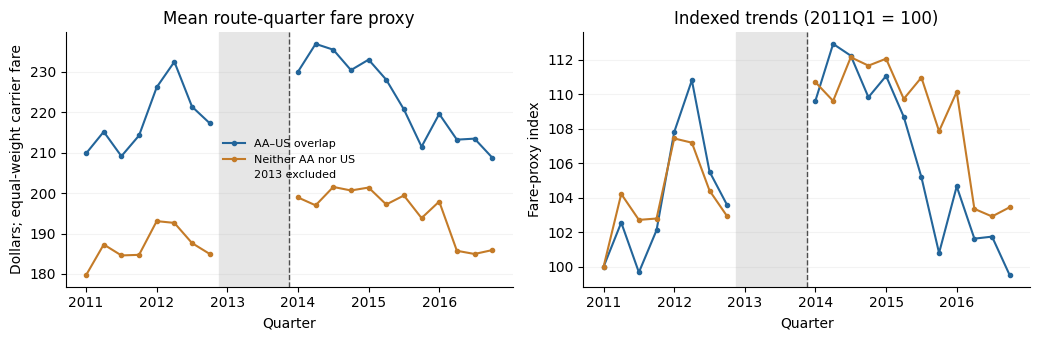

Figure 1 source values:
treated        0        1
2011Q1   179.711  209.811
2011Q2   187.292  215.187
2011Q3   184.593  209.130
2011Q4   184.734  214.257
2012Q1   193.075  226.190
2012Q2   192.633  232.485
2012Q3   187.645  221.378
2012Q4   184.963  217.296
2014Q1   198.932  230.017
2014Q2   196.981  236.908
2014Q3   201.530  235.475
2014Q4   200.657  230.421
2015Q1   201.378  233.012
2015Q2   197.191  228.045
2015Q3   199.421  220.701
2015Q4   193.828  211.484
2016Q1   197.927  219.585
2016Q2   185.740  213.228
2016Q3   184.950  213.475
2016Q4   185.909  208.789


In [9]:
quarterly = eda.groupby(["period", "treated"]).fare_proxy.mean().unstack("treated")
full_periods = pd.period_range("2011Q1", "2016Q4", freq="Q")
quarterly = quarterly.reindex(full_periods)
x = np.arange(len(full_periods))
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5))
for group, label, color in [(1, "AA–US overlap", "#23659A"), (0, "Neither AA nor US", "#C47B28")]:
    axes[0].plot(x, quarterly[group], marker="o", markersize=3, color=color, label=label)
    index = 100 * quarterly[group] / quarterly.loc[pd.Period("2011Q1"), group]
    axes[1].plot(x, index, marker="o", markersize=3, color=color, label=label)
for ax in axes:
    ax.axvspan(7.5, 11.5, color="0.9", label="2013 excluded")
    ax.axvline(11.5, color="0.3", linestyle="--", linewidth=1)
    ax.set_xticks([0, 4, 8, 12, 16, 20], ["2011", "2012", "2013", "2014", "2015", "2016"])
    ax.set_xlabel("Quarter")
    ax.grid(axis="y", alpha=0.15)
axes[0].set_title("Mean route-quarter fare proxy")
axes[0].set_ylabel("Dollars; equal-weight carrier fare")
axes[1].set_title("Indexed trends (2011Q1 = 100)")
axes[1].set_ylabel("Fare-proxy index")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT / "fare_trends.png", dpi=180, bbox_inches="tight")
plt.show()
print("Figure 1 source values:")
print(quarterly.dropna(how="all").round(3).to_string())
quarterly.to_csv(OUTPUT / "quarterly_fare_trends.csv")

### 2.11 A numerical finding and a concern
The following calculation is descriptive. It compares changes in annual **group means**, not route fixed-effects coefficients, and is affected by which routes are observed. It is not a causal estimate or a formal parallel-trends test. I also show the same diagnostic for routes observed in all eight pre-merger quarters to examine composition.

In [10]:
annual = pre.groupby(["year", "treated"]).fare_proxy.mean().unstack("treated")
pre_gap_log_pct = float(100 * (np.log(annual.loc[2012, 1] / annual.loc[2011, 1]) -
                               np.log(annual.loc[2012, 0] / annual.loc[2011, 0])))
print("Pre-merger annual means:")
print(annual.round(3).to_string())
print(f"Descriptive 2011–2012 difference in log growth: {pre_gap_log_pct:.3f} log-percentage points.")
pre_counts = pre.groupby("route").period.nunique()
balanced_routes = pre_counts.index[pre_counts == 8]
balanced_pre = pre.loc[pre.route.isin(balanced_routes)]
balanced_annual = balanced_pre.groupby(["year", "treated"]).fare_proxy.mean().unstack("treated")
balanced_gap = float(100 * (np.log(balanced_annual.loc[2012, 1] / balanced_annual.loc[2011, 1]) -
                            np.log(balanced_annual.loc[2012, 0] / balanced_annual.loc[2011, 0])))
print(f"Routes observed in all eight pre-merger quarters: {len(balanced_routes):,}")
print("Balanced-pre route counts by group:")
print(balanced_pre.groupby("treated").route.nunique().to_string())
print(f"Balanced-pre descriptive log-growth difference: {balanced_gap:.3f} log-percentage points.")
print(f"Key finding: before the merger, the fare proxy averaged ${balance.loc['fare_proxy', 'treated']:.2f} on overlap routes and ${balance.loc['fare_proxy', 'comparison']:.2f} on comparison routes.")
print("Concern: the fare levels, distances, carrier counts, and pre-period changes differ; neither a level gap nor a pre-period growth gap identifies the merger effect.")
summary = {
    "input_rows": len(carrier), "all_route_quarters": len(route_quarter),
    "eda_rows": len(eda), "eda_routes": eda.route.nunique(),
    "treated_routes": len(treated_routes), "control_routes": len(control_routes),
    "treated_pre_rows": int((pre.treated == 1).sum()),
    "control_pre_rows": int((pre.treated == 0).sum()),
    "pre_growth_gap_log_pct": pre_gap_log_pct, "balanced_pre_growth_gap_log_pct": balanced_gap,
    "fractional_saved_weights": fractional_weight_rows,
    "data_sha256": source_sha256, "action_threshold_pct": ACTION_THRESHOLD_PCT,
}
(OUTPUT / "eda_summary.json").write_text(json.dumps(summary, indent=2))
print("Summary for the proposal:")
print(json.dumps(summary, indent=2))

Pre-merger annual means:
treated        0        1
year                     
2011     184.143  212.098
2012     189.550  224.362
Descriptive 2011–2012 difference in log growth: 2.727 log-percentage points.
Routes observed in all eight pre-merger quarters: 1,115
Balanced-pre route counts by group:
treated
0    738
1    377
Balanced-pre descriptive log-growth difference: 1.652 log-percentage points.
Key finding: before the merger, the fare proxy averaged $218.26 on overlap routes and $186.87 on comparison routes.
Concern: the fare levels, distances, carrier counts, and pre-period changes differ; neither a level gap nor a pre-period growth gap identifies the merger effect.
Summary for the proposal:
{
  "input_rows": 140026,
  "all_route_quarters": 45065,
  "eda_rows": 25737,
  "eda_routes": 1653,
  "treated_routes": 418,
  "control_routes": 1235,
  "treated_pre_rows": 3192,
  "control_pre_rows": 7658,
  "pre_growth_gap_log_pct": 2.7273187190875285,
  "balanced_pre_growth_gap_log_pct": 1.6

### 2.12 What I will do next
1. Rebuild passenger totals and fare numerators from the raw ticket data in Python; audit the traffic-floor rule and operating-versus-marketing carrier mapping.
2. Fix the overlap definition and comparison rules before fitting the final treatment model. Use baseline route characteristics to assess common support; do not use post-merger characteristics for matching.
3. Plot and test pre-treatment event-study leads, report all results, and consider a longer pre-period. A non-rejection will not prove parallel trends.
4. Report sensitivity to fare construction, balanced panels, overlap persistence and comparison definitions. I will not interpret a statistically insignificant estimate as proof that the merger caused no harm.
5. Keep the merger and the remedies together as the treatment package. This design cannot separately identify what would have happened without the divestitures.

**Milestone status:** Part 2 EDA is completed on the supplied collapsed panel. Causal estimation, the dashboard and the final recommendation belong to later milestones.

**Sources**
- BTS DB1B: https://www.transtats.bts.gov/DatabaseInfo.asp?QO_VQ=EFI&Yv0x=D
- DOJ settlement: https://www.justice.gov/archives/opa/pr/justice-department-statement-us-district-court-finding-department-s-settlement-us
- Stata weighted collapse definitions: https://www.stata.com/manuals/dcollapse.pdf
- Course starter: https://github.com/RyanPiao/econ5200-student-notebooks/blob/main/5200/final-project-starter.ipynb

**Assistance:** I used ChatGPT to help review my code after writing it myself and debugging where I got stuck.